scan_id: 42450125
h5_path: /gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/42450125/42450125_pt_1.h5
volume scale factors (target / source): [0.8258317 0.8258317 1.       ]
slice-wise in-plane scale factors (target / source): [1. 1.]
translation is encoded in the affine offset; no rotation is used
crop bbox: (slice(9, 432, None), slice(8, 431, None), slice(0, 489, None))
display shape: (447, 447, 513)
basal display squish factor on axis 1: 1.28
squished basal slice shape: (349, 513)
padded basal slice shape: (447, 513)
h5 slice shape: (447, 513)
plotting with a 90 degree clockwise rotation


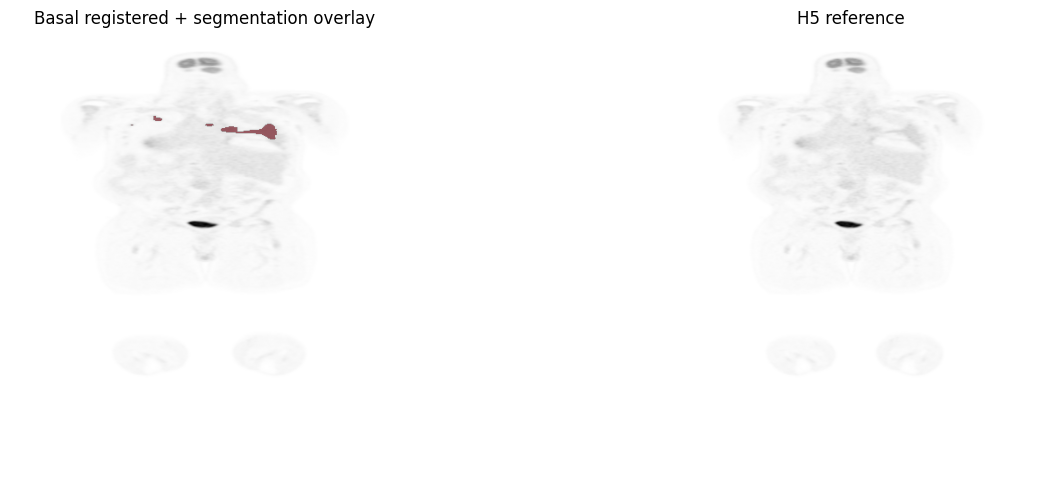

In [72]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
from scipy.ndimage import affine_transform

DATA_SCAN_CURATED_CSV = "/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/data_scan_curated.csv"
H5_ROOT = "/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5"
BASAL_ROOT = "/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/nibabel_rewrite_for_autopet3_flat"
SEG_ROOT = "/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/autopet3_predictions"


def compute_axis_aligned_affine(source_volume, target_volume):
    source_mask = source_volume > 0
    target_mask = target_volume > 0
    source_idx = np.argwhere(source_mask)
    target_idx = np.argwhere(target_mask)
    source_min = source_idx.min(axis=0)
    source_max = source_idx.max(axis=0)
    target_min = target_idx.min(axis=0)
    target_max = target_idx.max(axis=0)
    source_center = (source_min + source_max) / 2.0
    target_center = (target_min + target_max) / 2.0
    source_extent = np.maximum(source_max - source_min, 1)
    target_extent = np.maximum(target_max - target_min, 1)
    scale = target_extent / source_extent
    matrix = np.diag(1.0 / scale)
    offset = source_center - (target_center / scale)
    return matrix, offset, scale, source_center, target_center


def crop_to_shared_foreground(*volumes):
    shared_mask = np.zeros_like(volumes[0], dtype=bool)
    for volume in volumes:
        shared_mask |= volume > 0
    coords = np.argwhere(shared_mask)
    if coords.size == 0:
        return tuple(slice(0, size) for size in volumes[0].shape)
    lower = coords.min(axis=0)
    upper = coords.max(axis=0) + 1
    return tuple(slice(int(lower[axis]), int(upper[axis])) for axis in range(shared_mask.ndim))


def add_constant_border(volume, border_px=12):
    return np.pad(volume, border_px, mode="constant", constant_values=0)


def pad_to_shape(volume, target_shape):
    pad_width = []
    for current_size, target_size in zip(volume.shape, target_shape):
        deficit = max(int(target_size) - int(current_size), 0)
        left = deficit // 2
        right = deficit - left
        pad_width.append((left, right))
    return np.pad(volume, pad_width, mode="constant", constant_values=0)


def compute_slice_scale_2d(source_slice, target_slice):
    source_mask = source_slice > 0
    target_mask = target_slice > 0
    source_idx = np.argwhere(source_mask)
    target_idx = np.argwhere(target_mask)
    if source_idx.size == 0 or target_idx.size == 0:
        return np.array([1.0, 1.0])
    source_min = source_idx.min(axis=0)
    source_max = source_idx.max(axis=0)
    target_min = target_idx.min(axis=0)
    target_max = target_idx.max(axis=0)
    source_extent = np.maximum(source_max - source_min, 1)
    target_extent = np.maximum(target_max - target_min, 1)
    return target_extent / source_extent


def get_h5_filepath_for_scan(scan_id, scan_table=DATA_SCAN_CURATED_CSV):
    scan_df = pd.read_csv(scan_table, dtype=str)
    scan_df["accession"] = scan_df["accession"].astype(str).str.strip()
    matches = scan_df[scan_df["accession"] == str(scan_id)]
    if matches.empty:
        raise FileNotFoundError(f"No H5 filepath found for scan_id={scan_id} in {scan_table}")
    row = matches.iloc[0]
    relative_path = row["fullfile"] if "fullfile" in row.index else row["filepath"]
    return str(Path(H5_ROOT) / str(relative_path))


def plot_registration_for_scan(scan_id, squish_factor=1.28):
    basal_path = Path(BASAL_ROOT) / f"{scan_id}_0001.nii.gz"
    seg_path = Path(SEG_ROOT) / f"{scan_id}.nii.gz"
    h5_path = Path(get_h5_filepath_for_scan(scan_id))

    basal_dat = nib.load(str(basal_path)).get_fdata()
    seg_dat = nib.load(str(seg_path)).get_fdata()
    with h5py.File(str(h5_path), "r") as h5_file:
        h5_dat = h5_file["image"][:]

    basal_dat = np.transpose(basal_dat, (1, 0, 2))
    seg_dat = np.transpose(seg_dat, (1, 0, 2))

    matrix, offset, scale, source_center, target_center = compute_axis_aligned_affine(basal_dat, h5_dat)

    basal_dat_registered = affine_transform(
        basal_dat,
        matrix=matrix,
        offset=offset,
        output_shape=h5_dat.shape,
        order=1,
        mode="constant",
        cval=0.0,
    )
    seg_dat_registered = affine_transform(
        seg_dat,
        matrix=matrix,
        offset=offset,
        output_shape=h5_dat.shape,
        order=0,
        mode="constant",
        cval=0.0,
    )

    crop_bbox = crop_to_shared_foreground(basal_dat_registered, h5_dat, seg_dat_registered)
    border_px = 12
    basal_display = add_constant_border(basal_dat_registered[crop_bbox], border_px=border_px)
    h5_display = add_constant_border(h5_dat[crop_bbox], border_px=border_px)
    seg_display = add_constant_border(seg_dat_registered[crop_bbox], border_px=border_px)

    slice_index = int(np.clip(np.round(target_center[0]), 0, h5_dat.shape[0] - 1))
    local_slice = slice_index - crop_bbox[0].start + border_px
    h5_slice = h5_display[local_slice]
    basal_slice = basal_display[local_slice]
    seg_slice = seg_display[local_slice]

    slice_scale = compute_slice_scale_2d(basal_slice, h5_slice)
    display_squish_factor = float(squish_factor)
    squished_shape1 = max(1, int(np.round(basal_display.shape[1] / display_squish_factor)))

    basal_display_squished = affine_transform(
        basal_display,
        matrix=np.diag([1.0, display_squish_factor, 1.0]),
        offset=0.0,
        output_shape=(basal_display.shape[0], squished_shape1, basal_display.shape[2]),
        order=1,
        mode="constant",
        cval=0.0,
    )
    seg_display_squished = affine_transform(
        seg_display,
        matrix=np.diag([1.0, display_squish_factor, 1.0]),
        offset=0.0,
        output_shape=(seg_display.shape[0], squished_shape1, seg_display.shape[2]),
        order=0,
        mode="constant",
        cval=0.0,
    )

    basal_slice_squished = basal_display_squished[local_slice]
    seg_slice_squished = seg_display_squished[local_slice]
    basal_slice_padded = pad_to_shape(basal_slice_squished, h5_slice.shape)
    seg_slice_padded = pad_to_shape(seg_slice_squished, h5_slice.shape)

    print("scan_id:", scan_id)
    print("h5_path:", h5_path)
    print("volume scale factors (target / source):", scale)
    print("slice-wise in-plane scale factors (target / source):", slice_scale)
    print("translation is encoded in the affine offset; no rotation is used")
    print("crop bbox:", crop_bbox)
    print("display shape:", basal_display.shape)
    print("basal display squish factor on axis 1:", display_squish_factor)
    print("squished basal slice shape:", basal_slice_squished.shape)
    print("padded basal slice shape:", basal_slice_padded.shape)
    print("h5 slice shape:", h5_slice.shape)
    print("plotting with a 90 degree clockwise rotation")

    plt.figure(figsize=(15, 5))
    seg_overlay = np.rot90(seg_slice_padded, -1)
    seg_overlay = np.ma.masked_where(seg_overlay <= 0, seg_overlay)

    plt.subplot(1, 2, 1)
    plt.imshow(np.rot90(basal_slice_padded, -1), cmap="gray_r", origin="lower")
    plt.imshow(seg_overlay, cmap="Reds", alpha=0.6, vmin=0, vmax=1, origin="lower")
    plt.title("Basal registered + segmentation overlay")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(np.rot90(h5_slice, -1), cmap="gray_r", origin="lower")
    plt.title("H5 reference")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


# Example usage
plot_registration_for_scan("42450125", squish_factor = 1.28)


In [3]:
from pathlib import Path
import numpy as np
import nibabel as nib
import pydicom
import os
import pandas as pd

from pathlib import Path
import numpy as np
import nibabel as nib
import pandas as pd
from typing import Optional
from matplotlib.colors import Normalize, LinearSegmentedColormap
import matplotlib.pyplot as plt
import tqdm
import h5py


Case: 42450125
PET shape: (512, 512, 489)
Segmentation shape: (512, 512, 489)
Segmentation voxels: 203253
Excel label column: PET-jco
Excel label value: 1
Label shown: 1


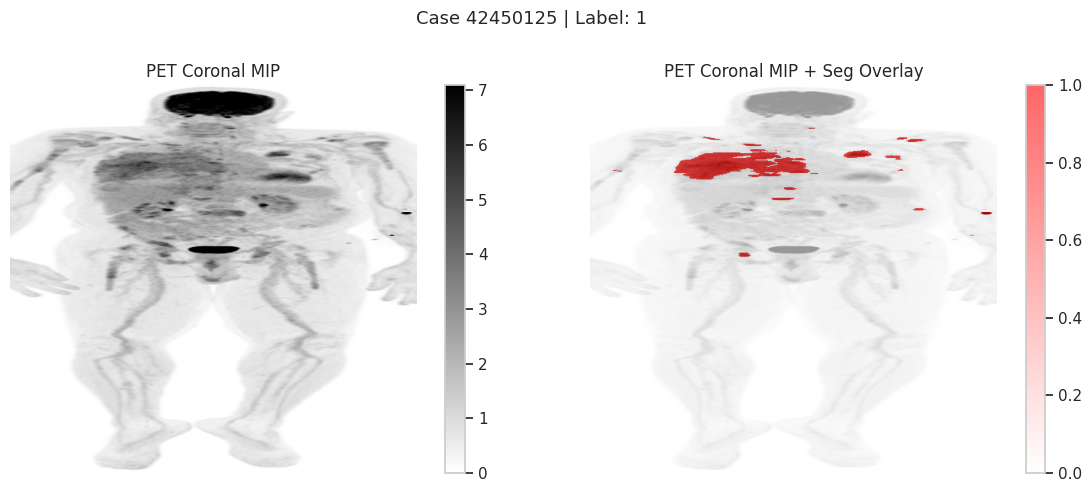

In [16]:
LABELS_EXCEL_PATH = '/gpfs/data/mayerhoeferlab/projects/myeloma/curated_status/Myeloma_master_ref_15_08_2025.xlsx'
_LABELS_DF_CACHE = None


def load_nifti_data(filepath: str) -> np.ndarray:
    """Load NIfTI file and return data array."""
    img = nib.load(filepath)
    return np.asarray(img.dataobj)


def get_case_label_from_excel(
    case_id: str,
    labels_excel: str = LABELS_EXCEL_PATH,
    id_column: str = "ACC",
    label_column: str = "PET-jco",
) -> Optional[str]:
    """Return PET_jco label text for case_id from curated excel, or None if unavailable."""
    global _LABELS_DF_CACHE

    if _LABELS_DF_CACHE is None:
        _LABELS_DF_CACHE = pd.read_excel(labels_excel)

    df = _LABELS_DF_CACHE
    if id_column not in df.columns or label_column not in df.columns:
        return None

    matches = df[df[id_column].astype(str) == str(case_id)]
    if matches.empty:
        return None

    value = matches.iloc[0][label_column]
    if pd.isna(value):
        return None
    return str(value)


def visualize_case(
    case_id: str,
    ct_dir: str = "/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/nibabel_rewrite_for_autopet3_flat",
    seg_dir: str = "/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/autopet3_predictions",
    true_label: Optional[str] = None,
    labels_excel: str = LABELS_EXCEL_PATH,
    id_column: str = "ACC",
    label_column: str = "PET-jco",
) -> None:
    """Visualize coronal PET MIP and PET+segmentation MIP overlay for a given case."""
    pet_path = Path(ct_dir) / f"{case_id}_0001.nii.gz"
    seg_path = Path(seg_dir) / f"{case_id}.nii.gz"

    if not pet_path.exists():
        print(f"PET file not found: {pet_path}")
        return
    if not seg_path.exists():
        print(f"Segmentation file not found: {seg_path}")
        return

    pet_data = load_nifti_data(str(pet_path))
    seg_data = load_nifti_data(str(seg_path))

    # Priority: explicit function argument > CSV PET_jco label > segmentation-derived fallback.
    seg_voxels = int(np.sum(seg_data > 0))
    excel_label = get_case_label_from_excel(
        case_id=case_id,
        labels_excel=labels_excel,
        id_column=id_column,
        label_column=label_column,
    )
    label_to_show = excel_label

    # Coronal MIP: project over the anterior-posterior axis (axis=1).
    pet_mip = np.max(pet_data, axis=1)
    seg_mip = np.max((seg_data > 0).astype(np.float32), axis=1)

    pet_nonzero = pet_mip[pet_mip > 0]
    pet_vmax = float(np.percentile(pet_nonzero, 99)) if pet_nonzero.size > 0 else 1.0
    pet_norm = Normalize(vmin=0.0, vmax=pet_vmax)

    # Colormap for segmentation: linear from white to pure red
    white_to_red_cmap = LinearSegmentedColormap.from_list("white_to_red", ["white", "red"])

    print(f"Case: {case_id}")
    print(f"PET shape: {pet_data.shape}")
    print(f"Segmentation shape: {seg_data.shape}")
    print(f"Segmentation voxels: {seg_voxels}")
    print(f"Excel label column: {label_column}")
    print(f"Excel label value: {excel_label}")
    print(f"Label shown: {label_to_show}")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # PET coronal MIP (grayscale)
    im1 = axes[0].imshow(pet_mip.T, cmap="gray_r", norm=pet_norm, origin="lower")
    axes[0].set_title("PET Coronal MIP")
    axes[0].axis("off")
    plt.colorbar(im1, ax=axes[0])

    # PET coronal MIP + segmentation coronal MIP overlay
    # PET is shown with alpha so the red segmentation overlay reads clearly.
    axes[1].imshow(pet_mip.T, cmap="gray_r", norm=pet_norm, alpha=1, origin="lower")
    #seg_masked = np.ma.masked_where(seg_mip.T <= 0, seg_mip.T)
    im2 = axes[1].imshow(seg_mip.T, cmap=white_to_red_cmap, alpha=.6, vmin=0, vmax=1, origin="lower")
    axes[1].set_title("PET Coronal MIP + Seg Overlay")
    axes[1].axis("off")
    plt.colorbar(im2, ax=axes[1])

    fig.suptitle(f"Case {case_id} | Label: {label_to_show}", fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

# Example usage
visualize_case("42450125")

In [3]:
PRED_DIR = Path("/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/autopet3_predictions")
LABELS_EXCEL = Path("/gpfs/data/mayerhoeferlab/projects/myeloma/curated_status/Myeloma_master_ref_15_08_2025.xlsx")
OUT_CSV = PRED_DIR / "segmentation_voxel_summary_with_excel_label.csv"

ID_COLUMN = "ACC"
LABEL_COLUMN = "PET-jco"

labels_df = pd.read_excel(LABELS_EXCEL)
def _normalize_case_id(x):
    s = str(x).strip()
    # Excel IDs can come in as floats like 10032528.0
    if s.endswith(".0"):
        s = s[:-2]
    return s

labels_df[ID_COLUMN] = labels_df[ID_COLUMN].map(_normalize_case_id)
label_map = dict(zip(labels_df[ID_COLUMN], labels_df[LABEL_COLUMN]))


In [9]:
rows = []
pred_files = sorted(PRED_DIR.glob("*.nii.gz"))

for seg_file in tqdm.tqdm(pred_files):
    case_id = seg_file.name.replace(".nii.gz", "")
    seg_data = np.asarray(nib.load(str(seg_file)).dataobj)
    seg_voxels = int(np.sum(seg_data > 0))
    excel_label = label_map.get(case_id, None)
    if pd.isna(excel_label):
        excel_label = None

    rows.append(
        {
            "case_id": case_id,
            "seg_voxels": seg_voxels,
            "excel_label": excel_label,
        }
    )

summary_df = pd.DataFrame(rows, columns=["case_id", "seg_voxels", "excel_label"])
summary_df.to_csv(OUT_CSV, index=False)

print(f"Processed files: {len(summary_df)}")
print(f"Saved CSV: {OUT_CSV}")
summary_df.head(10)

  0%|          | 0/1562 [00:00<?, ?it/s]

100%|██████████| 1562/1562 [10:28<00:00,  2.48it/s]

Processed files: 1562
Saved CSV: /gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/autopet3_predictions/segmentation_voxel_summary_with_excel_label.csv


,case_id,seg_voxels,excel_label
0,10002388,274,0.0
1,10024518,323,0.0
2,10032528,2235,0.0
3,10050499,67,0.0
4,10057383,78,0.0
5,10058653,142,0.0
6,10059140,30,0.0
7,10077198,84,0.0
8,10077727,501,0.0
9,10079537,104,1.0


Total test cases with segmentation voxel counts and excel labels: 592


/tmp/ipykernel_26847/2371836746.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="excel_label", y="seg_voxels", data=summary_df, palette = 'Set2', showfliers=False)


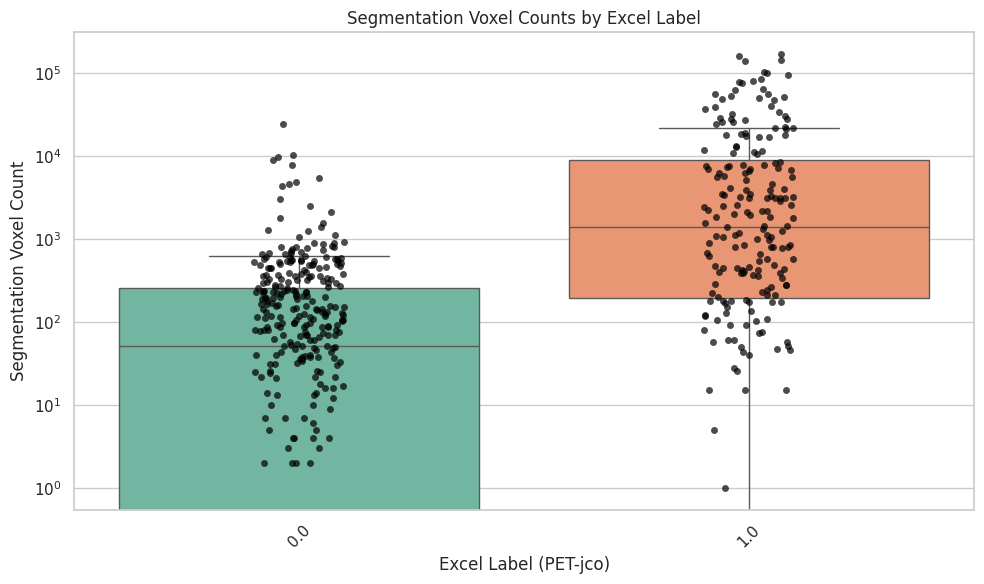

In [18]:
# box and strip plot of segmentation voxel counts by excel label
import matplotlib.pyplot as plt
import seaborn as sns 
sns.set(style="whitegrid")
summary_df = pd.read_csv(OUT_CSV)

# filter for test cases only
test_cases = pd.read_pickle('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/splits/train_val_test_split.pkl')['test']
summary_df = summary_df[summary_df['case_id'].isin(test_cases)]
print('Total test cases with segmentation voxel counts and excel labels:', len(summary_df))

# exclude PET_jco = 2
summary_df = summary_df[summary_df['excel_label'] != 2]
plt.figure(figsize=(10, 6))
sns.boxplot(x="excel_label", y="seg_voxels", data=summary_df, palette = 'Set2', showfliers=False)
sns.stripplot(x="excel_label", y="seg_voxels", data=summary_df, color="black", alpha=0.7)
plt.title("Segmentation Voxel Counts by Excel Label")
plt.xlabel("Excel Label (PET-jco)") 
plt.ylabel("Segmentation Voxel Count")
plt.xticks(rotation=45)
plt.yscale('log')
plt.tight_layout()
plt.show()

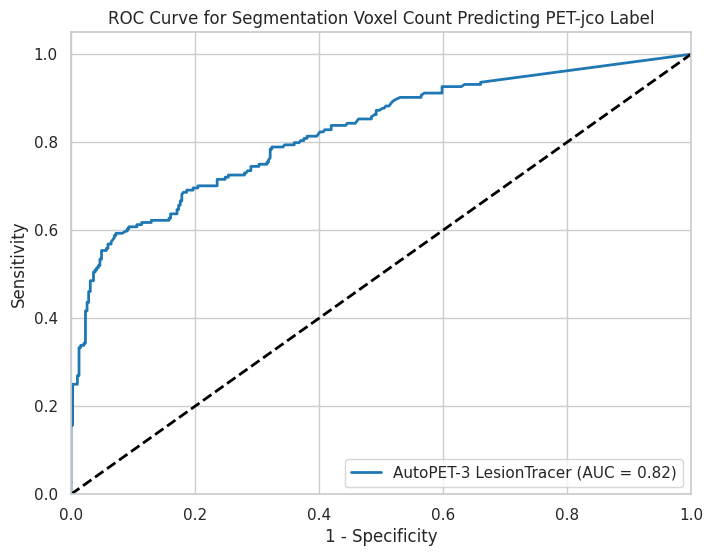

In [19]:
# ROC AUC curve with segmentation voxel count as predictor and excel label as binary outcome (PET_jco = 0 vs PET_jco = 1)
from sklearn.metrics import roc_curve, auc
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22']
binary_df = summary_df[summary_df['excel_label'].isin([0, 1])]
fpr, tpr, thresholds = roc_curve(binary_df['excel_label'], binary_df['seg_voxels'])
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color=colors[0], lw=2, label=f'AutoPET-3 LesionTracer (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='black', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('1 - Specificity')  
plt.ylabel('Sensitivity')
plt.title('ROC Curve for Segmentation Voxel Count Predicting PET-jco Label')
plt.legend(loc="lower right")

basal_dat shape: (512, 512, 489)
seg_dat shape: (512, 512, 489)
h5_dat shape: (440, 440, 489)
basal center: [255.5 255.5 244. ]
h5 center: [220. 219. 244.]
scale factors (h5 / basal): [0.8258317 0.8258317 1.       ]
affine matrix (output -> input):
[[1.21090047 0.         0.        ]
 [0.         1.21090047 0.        ]
 [0.         0.         1.        ]]
affine offset (output -> input): [-10.89810427  -9.68720379   0.        ]
shared crop bbox: (slice(9, 432, None), slice(8, 431, None), slice(0, 489, None))
border pixels added: 12
cropped basal shape: (447, 447, 513)
cropped h5 shape: (447, 447, 513)
cropped seg shape: (447, 447, 513)


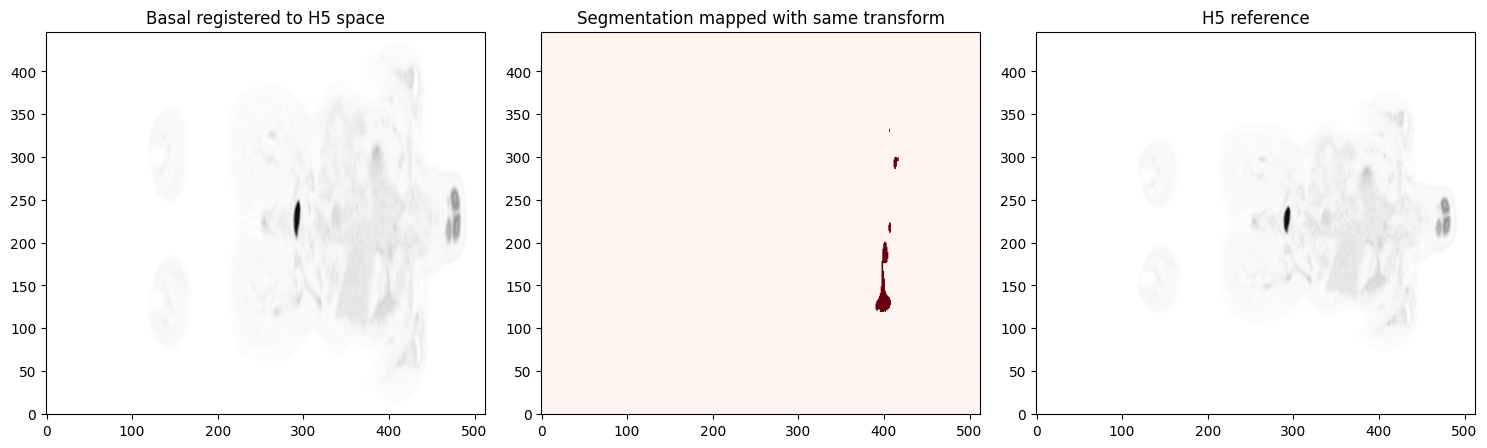

In [46]:
# Register basal_dat into h5_dat space using per-axis scaling + translation (no rotation),
# then apply the same transform to seg_dat.
from scipy.ndimage import affine_transform

basal_dat = nib.load("/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/nibabel_rewrite_for_autopet3_flat/42450125_0001.nii.gz").get_fdata()
seg_dat = nib.load("/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/autopet3_predictions/42450125.nii.gz").get_fdata()
h5_filename = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/42450125/42450125_pt_1.h5'
h5_dat = h5py.File(h5_filename, 'r')['image'][:]

basal_dat = np.transpose(basal_dat, (1, 0, 2))
seg_dat = np.transpose(seg_dat, (1, 0, 2))

# Estimate scaling from foreground extents in each axis.
basal_mask = basal_dat > 0
h5_mask = h5_dat > 0

basal_idx = np.argwhere(basal_mask)
h5_idx = np.argwhere(h5_mask)

basal_min = basal_idx.min(axis=0)
basal_max = basal_idx.max(axis=0)
h5_min = h5_idx.min(axis=0)
h5_max = h5_idx.max(axis=0)

basal_center = (basal_min + basal_max) / 2.0
h5_center = (h5_min + h5_max) / 2.0
basal_extent = np.maximum(basal_max - basal_min, 1)
h5_extent = np.maximum(h5_max - h5_min, 1)
scale = h5_extent / basal_extent

# affine_transform maps output coordinates -> input coordinates.
# We want x_input = (x_output - h5_center) / scale + basal_center.
matrix = np.diag(1.0 / scale)
offset = basal_center - (h5_center / scale)

basal_dat_registered = affine_transform(
    basal_dat,
    matrix=matrix,
    offset=offset,
    output_shape=h5_dat.shape,
    order=1,
    mode='constant',
    cval=0.0,
)
seg_dat_registered = affine_transform(
    seg_dat,
    matrix=matrix,
    offset=offset,
    output_shape=h5_dat.shape,
    order=0,
    mode='constant',
    cval=0.0,
)

print('basal_dat shape:', basal_dat.shape)
print('seg_dat shape:', seg_dat.shape)
print('h5_dat shape:', h5_dat.shape)
print('basal center:', basal_center)
print('h5 center:', h5_center)
print('scale factors (h5 / basal):', scale)
print('affine matrix (output -> input):')
print(matrix)
print('affine offset (output -> input):', offset)

# Crop both registered basal and h5 to a shared foreground bounding box, then add a small border.
def bbox_from_mask(mask):
    coords = np.argwhere(mask)
    if coords.size == 0:
        return tuple(slice(0, s) for s in mask.shape)
    lo = coords.min(axis=0)
    hi = coords.max(axis=0) + 1
    return tuple(slice(int(lo[i]), int(hi[i])) for i in range(mask.ndim))

border_px = 12
shared_mask = (basal_dat_registered > 0) | (h5_dat > 0) | (seg_dat_registered > 0)
shared_bbox = bbox_from_mask(shared_mask)

basal_crop = basal_dat_registered[shared_bbox]
h5_crop = h5_dat[shared_bbox]
seg_crop = seg_dat_registered[shared_bbox]

basal_plot = np.pad(basal_crop, border_px, mode='constant', constant_values=0)
h5_plot = np.pad(h5_crop, border_px, mode='constant', constant_values=0)
seg_plot = np.pad(seg_crop, border_px, mode='constant', constant_values=0)

print('shared crop bbox:', shared_bbox)
print('border pixels added:', border_px)
print('cropped basal shape:', basal_plot.shape)
print('cropped h5 shape:', h5_plot.shape)
print('cropped seg shape:', seg_plot.shape)

# Choose a representative slice near the h5 center so the view stays in-bounds.
sli = int(np.clip(np.round(h5_center[0]), 0, h5_dat.shape[0] - 1))

# Slice through the cropped arrays. Since we added a border, the visual padding is preserved.
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(basal_plot[sli - shared_bbox[0].start + border_px, :, :], cmap='gray_r', origin='lower')
plt.title('Basal registered to H5 space')
plt.subplot(1, 3, 2)
plt.imshow(seg_plot[sli - shared_bbox[0].start + border_px, :, :], cmap='Reds', origin='lower')
plt.title('Segmentation mapped with same transform')
plt.subplot(1, 3, 3)
plt.imshow(h5_plot[sli - shared_bbox[0].start + border_px, :, :], cmap='gray_r', origin='lower')
plt.title('H5 reference')
plt.tight_layout()
plt.show()


scale factors (target / source): [0.8258317 0.8258317 1.       ]
translation is encoded in the affine offset; no rotation is used
crop bbox: (slice(9, 432, None), slice(8, 431, None), slice(0, 489, None))
display shape: (447, 447, 513)
basal display squish factor on axis 0: 1.28
squished basal slice shape: (349, 513)
padded basal slice shape: (447, 513)
h5 slice shape: (447, 513)
plotting with a 90 degree clockwise rotation


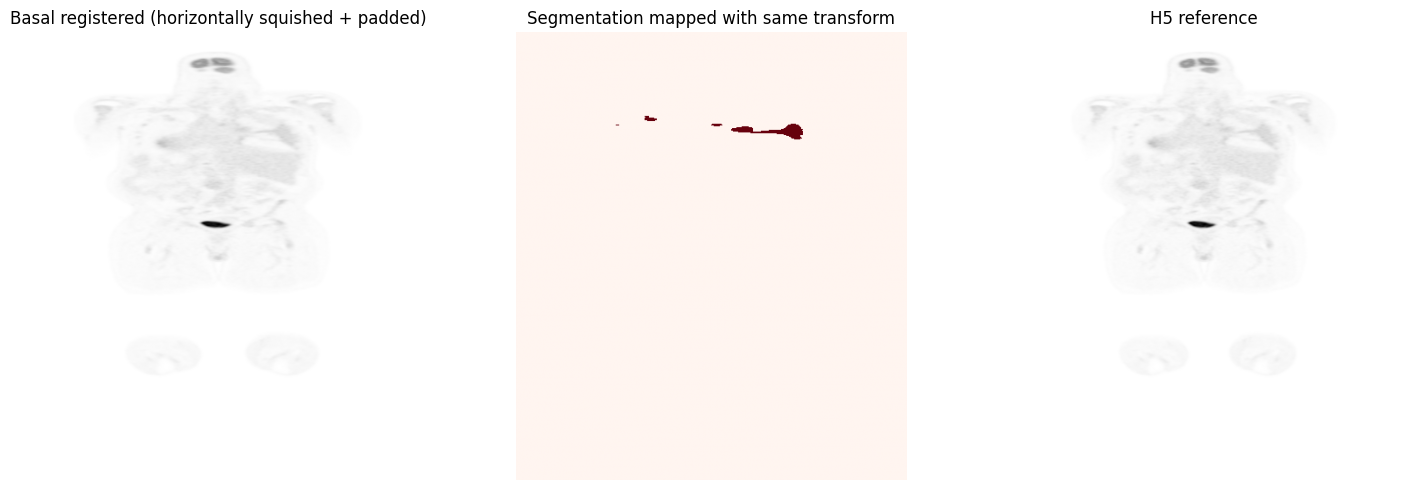

In [64]:
from scipy.ndimage import affine_transform


def compute_axis_aligned_affine(source_volume, target_volume):
    source_mask = source_volume > 0
    target_mask = target_volume > 0

    source_idx = np.argwhere(source_mask)
    target_idx = np.argwhere(target_mask)

    source_min = source_idx.min(axis=0)
    source_max = source_idx.max(axis=0)
    target_min = target_idx.min(axis=0)
    target_max = target_idx.max(axis=0)

    source_center = (source_min + source_max) / 2.0
    target_center = (target_min + target_max) / 2.0
    source_extent = np.maximum(source_max - source_min, 1)
    target_extent = np.maximum(target_max - target_min, 1)
    scale = target_extent / source_extent

    # Output coordinates -> input coordinates for scipy.ndimage.affine_transform.
    matrix = np.diag(1.0 / scale)
    offset = source_center - (target_center / scale)
    return matrix, offset, scale, source_center, target_center


def crop_to_shared_foreground(*volumes):
    shared_mask = np.zeros_like(volumes[0], dtype=bool)
    for volume in volumes:
        shared_mask |= volume > 0

    coords = np.argwhere(shared_mask)
    if coords.size == 0:
        return tuple(slice(0, size) for size in volumes[0].shape)

    lower = coords.min(axis=0)
    upper = coords.max(axis=0) + 1
    return tuple(slice(int(lower[axis]), int(upper[axis])) for axis in range(shared_mask.ndim))


def add_constant_border(volume, border_px=12):
    return np.pad(volume, border_px, mode='constant', constant_values=0)


def pad_to_shape(volume, target_shape):
    pad_width = []
    for current_size, target_size in zip(volume.shape, target_shape):
        deficit = max(int(target_size) - int(current_size), 0)
        left = deficit // 2
        right = deficit - left
        pad_width.append((left, right))
    return np.pad(volume, pad_width, mode='constant', constant_values=0)


basal_dat = nib.load("/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/nibabel_rewrite_for_autopet3_flat/42450125_0001.nii.gz").get_fdata()
seg_dat = nib.load("/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/autopet3_predictions/42450125.nii.gz").get_fdata()
with h5py.File('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/42450125/42450125_pt_1.h5', 'r') as h5_file:
    h5_dat = h5_file['image'][:]

basal_dat = np.transpose(basal_dat, (1, 0, 2))
seg_dat = np.transpose(seg_dat, (1, 0, 2))

matrix, offset, scale, source_center, target_center = compute_axis_aligned_affine(basal_dat, h5_dat)

basal_registered = affine_transform(
    basal_dat,
    matrix=matrix,
    offset=offset,
    output_shape=h5_dat.shape,
    order=1,
    mode='constant',
    cval=0.0,
)
seg_registered = affine_transform(
    seg_dat,
    matrix=matrix,
    offset=offset,
    output_shape=h5_dat.shape,
    order=0,
    mode='constant',
    cval=0.0,
)

crop_bbox = crop_to_shared_foreground(basal_registered, h5_dat, seg_registered)
border_px = 12
basal_display = add_constant_border(basal_registered[crop_bbox], border_px=border_px)
h5_display = add_constant_border(h5_dat[crop_bbox], border_px=border_px)
seg_display = add_constant_border(seg_registered[crop_bbox], border_px=border_px)

slice_index = int(np.clip(np.round(target_center[0]), 0, h5_dat.shape[0] - 1))
local_slice = slice_index - crop_bbox[0].start + border_px
h5_slice = h5_display[local_slice]

# Squish axis 0 of the pre-rotated slice so it appears horizontally squished after rotation.
display_squish_factor = 1.28
basal_slice = basal_display[local_slice]
squished_shape0 = max(1, int(np.round(basal_slice.shape[0] / display_squish_factor)))
basal_slice_squished = affine_transform(
    basal_slice,
    matrix=np.diag([display_squish_factor, 1.0]),
    offset=0.0,
    output_shape=(squished_shape0, basal_slice.shape[1]),
    order=1,
    mode='constant',
    cval=0.0,
)
basal_slice_padded = pad_to_shape(basal_slice_squished, h5_slice.shape)

print('scale factors (target / source):', scale)
print('translation is encoded in the affine offset; no rotation is used')
print('crop bbox:', crop_bbox)
print('display shape:', basal_display.shape)
print('basal display squish factor on axis 0:', display_squish_factor)
print('squished basal slice shape:', basal_slice_squished.shape)
print('padded basal slice shape:', basal_slice_padded.shape)
print('h5 slice shape:', h5_slice.shape)
print('plotting with a 90 degree clockwise rotation')

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(np.rot90(basal_slice_padded, -1), cmap='gray_r', origin='lower')
plt.title('Basal registered (horizontally squished + padded)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.rot90(seg_display[local_slice], -1), cmap='Reds', origin='lower')
plt.title('Segmentation mapped with same transform')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(np.rot90(h5_slice, -1), cmap='gray_r', origin='lower')
plt.title('H5 reference')
plt.axis('off')

plt.tight_layout()
plt.show()


In [42]:
print(seg_dat.shape)
print(h5_dat.shape)
print(basal_dat.shape)

(512, 512, 489)
(440, 440, 489)
(512, 512, 489)
